# Hubs and scale-free structure in a Facebook friendship network

**Goal:** describe the structure of a real social network: its size, how connected it is, which members act as hubs, and whether its degree distribution is scale-free (power-law) rather than random (Poisson).

**Data:** the *ego-Facebook* network from the [Stanford SNAP collection](https://snap.stanford.edu/data/ego-Facebook.html), with 4,039 anonymised users and 88,234 friendships (McAuley & Leskovec, 2012). The file is downloaded at run time and not redistributed here.

**Tools:** `networkx`, `pandas`, `matplotlib`.

In [1]:
import gzip
import io
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

URL = "https://snap.stanford.edu/data/facebook_combined.txt.gz"
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

INK, MUTED, GRID, ACCENT, SOFT, HUB = "#1d1d1f", "#6e6e73", "#e5e5ea", "#2a78d6", "#b9c6d6", "#e34948"
plt.rcParams.update({
    "font.size": 10, "text.color": INK, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "savefig.dpi": 170, "savefig.bbox": "tight", "savefig.facecolor": "white",
})

## 1. Loading the graph and basic measures

In [2]:
raw = urllib.request.urlopen(URL, timeout=60).read()
G = nx.read_edgelist(io.StringIO(gzip.decompress(raw).decode()), nodetype=int)

n, m = G.number_of_nodes(), G.number_of_edges()
summary = pd.Series({
    "Nodes (users)": f"{n:,}",
    "Edges (friendships)": f"{m:,}",
    "Average degree": f"{2 * m / n:.2f}",
    "Density": f"{nx.density(G):.4f}",
    "Average clustering coefficient": f"{nx.average_clustering(G):.3f}",
    "Average shortest path length": f"{nx.average_shortest_path_length(G):.2f}",
    "Connected components": str(nx.number_connected_components(G)),
})
summary.to_frame("value")

,value
Nodes (users),"4,039"
Edges (friendships),"88,234"
Average degree,43.69
Density,0.0108
Average clustering coefficient,0.606
Average shortest path length,3.69
Connected components,1


## 2. Who are the hubs?

In [3]:
deg = dict(G.degree())
btw = nx.betweenness_centrality(G, k=1000, seed=42)
hubs = (pd.DataFrame({"degree": deg, "betweenness": btw})
        .sort_values("degree", ascending=False).head(8).round(3))
hubs.index.name = "node"
hubs

,degree,betweenness
node,,
107,1045,0.485
1684,792,0.345
1912,755,0.223
3437,547,0.227
0,347,0.152
2543,294,0.007
2347,291,0.003
1888,254,0.000


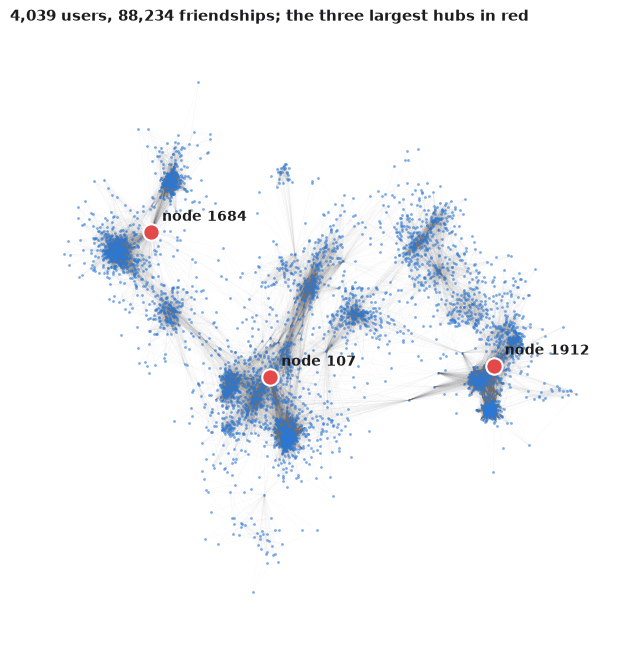

In [4]:
top3 = list(hubs.index[:3])
pos = nx.spring_layout(G, seed=7, iterations=60)
fig, ax = plt.subplots(figsize=(8, 8))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.04, width=0.3, edge_color=MUTED)
others = [v for v in G if v not in top3]
nx.draw_networkx_nodes(G, pos, nodelist=others, ax=ax, node_size=4, node_color=ACCENT, alpha=0.6, linewidths=0)
nx.draw_networkx_nodes(G, pos, nodelist=top3, ax=ax, node_size=140, node_color=HUB, edgecolors="white", linewidths=1.5)
for v in top3:
    ax.annotate(f"node {v}", pos[v], xytext=(8, 8), textcoords="offset points", fontsize=10, color=INK, weight="bold")
ax.set_axis_off()
ax.set_title("4,039 users, 88,234 friendships; the three largest hubs in red")
fig.savefig(FIG / "01_network_hubs.png")

## 3. Communities

In [5]:
communities = nx.community.louvain_communities(G, seed=42)
sizes = sorted((len(c) for c in communities), reverse=True)
print(f"{len(communities)} communities, modularity {nx.community.modularity(G, communities):.3f}")
print("largest:", sizes[:10])

16 communities, modularity 0.835
largest: [548, 535, 435, 431, 423, 350, 324, 237, 226, 206]


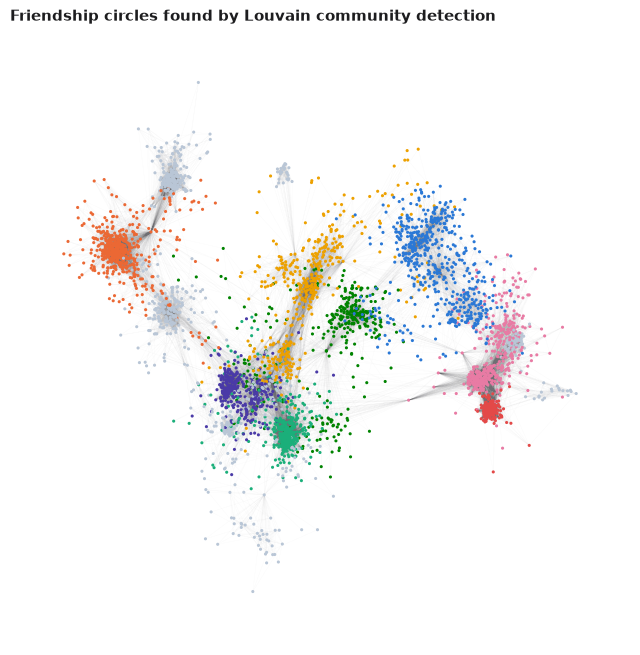

In [6]:
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
ranked = sorted(communities, key=len, reverse=True)
color = {}
for i, c in enumerate(ranked):
    for v in c:
        color[v] = palette[i] if i < len(palette) else SOFT
fig, ax = plt.subplots(figsize=(8, 8))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.03, width=0.3, edge_color=MUTED)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=5, node_color=[color[v] for v in G], linewidths=0)
ax.set_axis_off()
ax.set_title("Friendship circles found by Louvain community detection")
fig.savefig(FIG / "02_communities.png")

## 4. Is the network scale-free?

max degree 1045, median degree 25, users with ≤ 25 friends: 51%


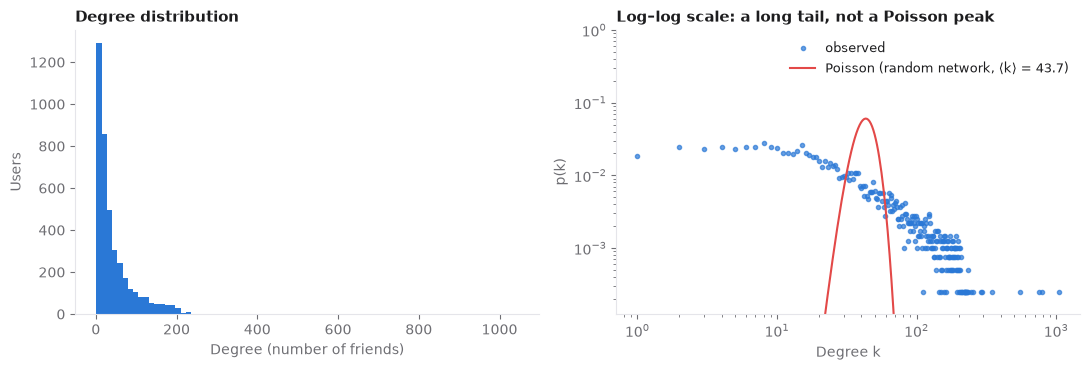

In [7]:
degrees = np.array([d for _, d in G.degree()])
counts = Counter(degrees)
k = np.array(sorted(counts))
pk = np.array([counts[x] for x in k]) / n

mean_k = degrees.mean()
from scipy.stats import poisson
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(degrees, bins=80, color=ACCENT)
axes[0].set(title="Degree distribution", xlabel="Degree (number of friends)", ylabel="Users")
axes[1].loglog(k, pk, "o", ms=3, color=ACCENT, alpha=0.7, label="observed")
kk = np.arange(1, degrees.max() + 1)
axes[1].loglog(kk, poisson.pmf(kk, mean_k), color=HUB, lw=1.5, label=f"Poisson (random network, ⟨k⟩ = {mean_k:.1f})")
axes[1].set_ylim(pk.min() / 2, 1)
axes[1].set(title="Log–log scale: a long tail, not a Poisson peak", xlabel="Degree k", ylabel="p(k)")
axes[1].legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "03_degree_distribution.png")
print(f"max degree {degrees.max()}, median degree {np.median(degrees):.0f}, users with ≤ 25 friends: {(degrees <= 25).mean():.0%}")

## 5. Conclusions

1. **Hubs dominate:** nodes 107, 1684 and 1912 have hundreds of connections, while the median user has only about 25.
2. **The network is not random.** Its degree distribution has a long, heavy tail on the log–log plot, very different from the narrow Poisson peak a random network with the same average degree would produce. This is the signature of a scale-free network (Barabási, 2016).
3. **Friendships form tight circles:** the average clustering coefficient is 0.61, Louvain community detection finds 16 friendship circles (modularity 0.84), and any two users are on average only 3.7 steps apart.

*References:* McAuley, J., & Leskovec, J. (2012). Learning to discover social circles in ego networks. *NIPS*. Barabási, A.-L. (2016). *Network Science*. Cambridge University Press.